# PoC poc-01 — Factor timing con gate de confiabilidad

Resultados de `scripts_run_timing.py`. Evaluación fuera de muestra 2005-01 a 2026-08, costo base 10 pb por unidad de rotación. Las figuras se guardan en `reports/figures/poc-01/` para reutilizarlas en la demo.

In [1]:
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from factorlab.config import DATA_INTERIM, REPORTS
FIG = REPORTS / "figures" / "poc-01"; FIG.mkdir(parents=True, exist_ok=True)
r = pd.read_parquet(DATA_INTERIM / "timing_results.parquet")
m = pd.read_parquet(DATA_INTERIM / "timing_metrics.parquet")
s = json.loads((DATA_INTERIM / "timing_summary.json").read_text())
NAMES = {"ew": "Equal-weight", "mom12": "Momentum 12m (ingenua)", "primary": "Modelo principal (MLP)", "gated": "Principal + gate"}
COL = {"ew": "#555555", "mom12": "#c9a227", "primary": "#2a6fdb", "gated": "#d1495b"}
print(s["veredicto"], "| abstención", s["meses_abstencion"], "/", s["meses_eval"], "| precisión", round(s["precision_abstencion"], 3))

NO FUNCIONA | abstención 146 / 260 | precisión 0.425


## 1. Rendimiento acumulado (neto de 10 pb)

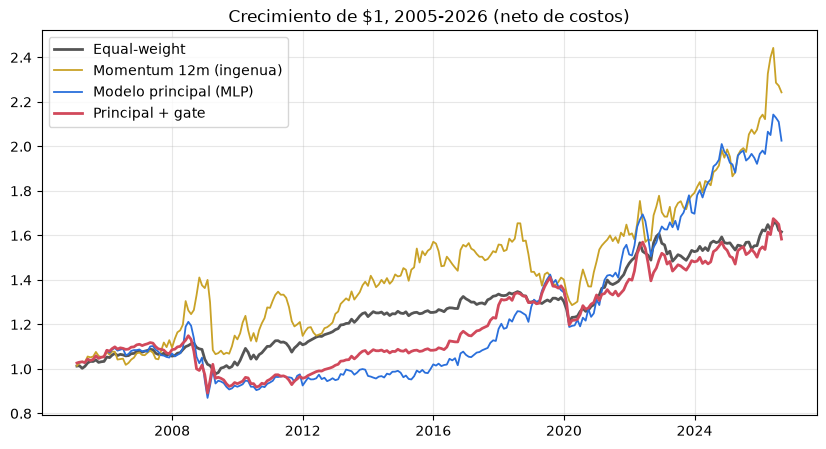

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
for k in NAMES:
    ax.plot((1 + r[f"ret_{k}"]).cumprod(), label=NAMES[k], color=COL[k], lw=2 if k in ("gated", "ew") else 1.3)
ax.set_title("Crecimiento de $1, 2005-2026 (neto de costos)"); ax.legend(); ax.grid(alpha=.3)
fig.savefig(FIG / "acumulado.png", dpi=150, bbox_inches="tight")

## 2. ¿Cuándo se abstuvo el gate?

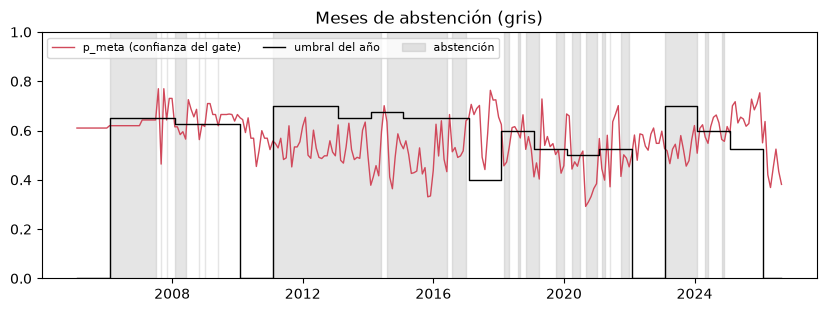

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(r.index, r.p_meta, color="#d1495b", lw=1, label="p_meta (confianza del gate)")
ax.step(r.index, r.threshold, color="black", lw=1, where="post", label="umbral del año")
ax.fill_between(r.index, 0, 1, where=r.abstain, color="#999", alpha=.25, transform=ax.get_xaxis_transform(), label="abstención")
ax.set_ylim(0, 1); ax.legend(loc="upper left", ncol=3, fontsize=8); ax.set_title("Meses de abstención (gris)")
fig.savefig(FIG / "abstencion.png", dpi=150, bbox_inches="tight")

## 3. Métricas por estrategia, costo y subperiodo

In [4]:
tab = m[(m.costo == "10pb") & (m.periodo == "2005-2026")].set_index("estrategia").loc[list(NAMES)]
tab[["retorno_anual", "volatilidad", "sharpe", "max_drawdown", "rotacion_mensual"]].round(3)

,retorno_anual,volatilidad,sharpe,max_drawdown,rotacion_mensual
estrategia,,,,,
ew,0.022,0.042,0.550,-0.123,0.000
mom12,0.038,0.097,0.436,-0.245,0.381
primary,0.033,0.082,0.440,-0.282,0.754
gated,0.021,0.065,0.361,-0.224,0.487


In [5]:
m[m.periodo == "2005-2026"].pivot(index="estrategia", columns="costo", values="sharpe").loc[list(NAMES)].round(3)

costo,0pb,10pb,25pb
estrategia,,,
ew,0.550,0.550,0.550
mom12,0.482,0.436,0.365
primary,0.552,0.440,0.273
gated,0.453,0.361,0.223


In [6]:
m[m.costo == "10pb"].pivot(index="estrategia", columns="periodo", values="sharpe").loc[list(NAMES)].round(3)

periodo,2005-2009,2005-2026,2010-2019,2020-2026
estrategia,,,,
ew,0.106,0.550,0.762,0.622
mom12,0.275,0.436,0.302,0.742
primary,-0.107,0.440,0.696,0.711
gated,-0.118,0.361,0.985,0.343


## 4. Calibración del gate: ¿su confianza significa algo?

AUC fuera de muestra del gate: 0.428


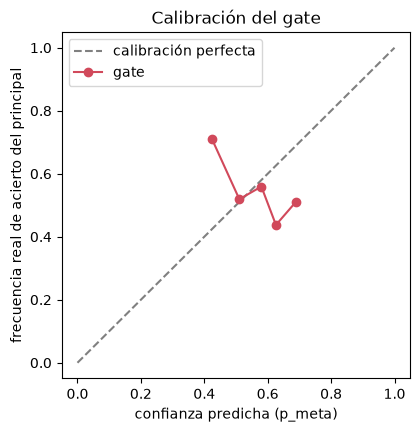

In [7]:
ok = r.meta_label.notna()
pt, pp = calibration_curve(r.loc[ok, "meta_label"], r.loc[ok, "p_meta"], n_bins=5, strategy="quantile")
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], "--", color="gray", label="calibración perfecta")
ax.plot(pp, pt, "o-", color="#d1495b", label="gate")
ax.set_xlabel("confianza predicha (p_meta)"); ax.set_ylabel("frecuencia real de acierto del principal")
ax.legend(); ax.set_title("Calibración del gate")
fig.savefig(FIG / "calibracion.png", dpi=150, bbox_inches="tight")
from sklearn.metrics import roc_auc_score
print("AUC fuera de muestra del gate:", round(roc_auc_score(r.loc[ok, "meta_label"], r.loc[ok, "p_meta"]), 3))

## 5. Qué factores elige el modelo

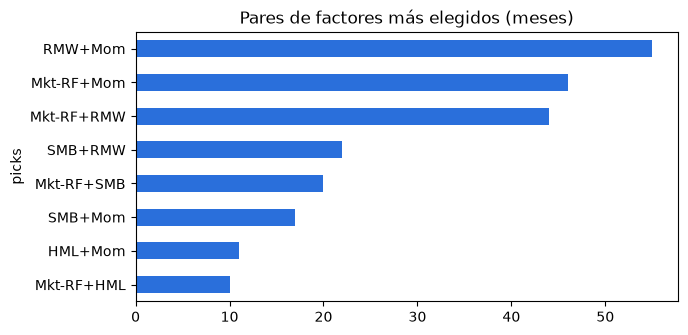

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
r.picks.value_counts().head(8).sort_values().plot.barh(ax=ax, color="#2a6fdb")
ax.set_title("Pares de factores más elegidos (meses)")
fig.savefig(FIG / "picks.png", dpi=150, bbox_inches="tight")